# Lab 3 · Diffusion-based search for wave equations

We search for a graph of operators on a sampled wave field. For a proposed graph with branches $\phi_j$, the equation is

$$u_{tt}=\sum_{j=1}^{m}\theta_j\phi_j(u,u_t).$$

Graph generation chooses the branches. A weak-form fit estimates their coefficients. Validation selects the graph, and a separate rollout tests how well the equation propagates the wave from two initial snapshots.

## 1. Imports and settings

In [ ]:
import json
import os
import sys
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, Markdown, display
from threadpoolctl import threadpool_limits

ROOT = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "lab3" / "wave_data.py").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from lab3.diffusion import training_rows
from lab3.experiment import (
    INITIAL,
    INTERVENTION_SEEDS,
    METHODS,
    WINDOWS,
    initial_pool,
    search,
)
from lab3.extensions import LAB1_GRAPH
from lab3.fitting import Scorer
from lab3.forecast_plots import (
    field_snapshots,
    forecast_comparison,
    forecast_diagnostics,
    heldout_fields,
    representative_run,
    sampler_forecast_errors,
    selected_forecast_errors,
    tuned_residuals,
    unrestricted_fields,
    wavefront_maps,
    wavefront_surfaces,
)
from lab3.forecast_tuning import graph_tuple
from lab3.grammar import LAPLACIAN, MIXED, TOKENS, encode, format_expr
from lab3.phase_drift import phase_drift_estimate, plot_phase_drift
from lab3.report import (
    REFERENCES,
    audit_text,
    example_trajectory,
    method_rows,
    plot_equation_graphs,
    plot_equation_records,
    plot_interventions,
    plot_predictions,
    plot_scores,
    plot_trajectory,
    proposal_variety,
    report_sampler_comparison,
    scores_are_flat,
    symbolic_equations,
)
from lab3.wave_data import coefficient_sign, make_blocks, synthetic

RESULTS = Path(os.environ.get("WAVE_LAB3_RESULTS", ROOT / "lab3" / "results"))
SEED = 11
DEMO_BUDGET = INITIAL + 6
LEAVES = ("u", "u_t")
SHOW_ANIMATION = False

In [2]:
def read_results(filename):
    path = RESULTS / filename
    return json.loads(path.read_text(encoding="utf-8")) if path.is_file() else None


def show_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
        *("| " + " | ".join(map(str, row)) + " |" for row in rows),
    ]
    display(Markdown("\n".join(lines)))

## 2. Generate a wave field and assemble weak rows

The demonstration field superposes nine analytic modes satisfying $u_{tt}=0.85\,\Delta u+0.72\,u_{xy}$. The samples form an array with axes $(t,x,y,z)$. Training, validation, and test use disjoint time ranges of the same field.

Each weak row averages over a compact space-time stencil. For outer linear derivatives, the derivative stencil acts on the test-function weights. The target vector $\mathbf y$ contains weak measurements of $u_{tt}$. Each column of $\mathbf X$ contains weak measurements of one graph branch and has the same row ordering as $\mathbf y$.

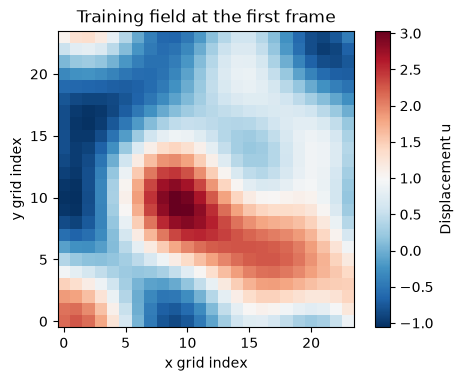

| Split | Frames | Weak rows |
| --- | --- | --- |
| Train | 120 | 3000 |
| Validation | 60 | 1400 |
| Test | 60 | 1400 |

Field shape (t, x, y, z): (240, 24, 24, 24)
Known-graph design matrix: (3000, 2)


In [3]:
wave = synthetic(mixed=True)
train, validation, test = (make_blocks(wave, split) for split in range(3))

fig, ax = plt.subplots(figsize=(5.2, 3.7), layout="constrained")
t, z = 0, wave.u.shape[-1] // 2
image = ax.imshow(wave.u[t, :, :, z].T, origin="lower", cmap="RdBu_r")
ax.set(title="Training field at the first frame", xlabel="x grid index", ylabel="y grid index")
fig.colorbar(image, ax=ax, label="Displacement u")
plt.show()

show_table(
    ("Split", "Frames", "Weak rows"),
    ((label, span.stop - span.start, len(rows.target))
     for label, (span, _), rows in zip(
         ("Train", "Validation", "Test"), wave.splits, (train, validation, test), strict=True
     )),
)
print("Field shape (t, x, y, z):", wave.u.shape)
print("Known-graph design matrix:", train.matrix(wave.truth).shape)

## 3. Fit, shuffle, and score two graphs

The Lab 1 baseline has one shared coefficient for $\Delta u$ and zero forcing. The known graph also contains $u_{xy}$. Fit each graph on clean training rows, then refit it on the same training data with snapshots shuffled within 2-frame and 12-frame windows. Branch retention requires support and the same coefficient sign before and after shuffling.

The search score is $J(G)=\operatorname{NMSE}_{\text{val}}+0.0015\,C(G)+0.035\,[1-R(G)]$, where $C$ counts operators and coefficients and $R$ averages branch retention over the mild shuffles. Eligibility also requires full rank and support for every coefficient on clean training data. Weak NMSE measures acceleration residuals evaluated on a sampled field. Forecast NMSE measures displacement errors across frames generated by a rollout.

In [4]:
mild, strong = (
    [make_blocks(wave, 0, window, seed) for seed in INTERVENTION_SEEDS]
    for window in WINDOWS
)
scorer = Scorer(train, validation, test, mild, strong, coefficient_sign)

rows = []
with threadpool_limits(limits=1):
    for label, graph in (("Lab 1", LAB1_GRAPH), ("Known graph", wave.truth)):
        evaluation = scorer.evaluate(graph)
        for branch, theta, sd, kept, retention in zip(
            graph, evaluation.fit.theta, evaluation.fit.sd, evaluation.fit.kept,
            evaluation.mild_support, strict=True,
        ):
            rows.append((label, format_expr(branch), f"{theta:.6g}", f"{sd:.6g}",
                         bool(kept), f"{retention:.0%}", f"{evaluation.score():.6g}"))
show_table(
    ("Graph", "Branch", "Coefficient", "Marginal SD", "Supported", "Mild retention", "Graph score"),
    rows,
)

| Graph | Branch | Coefficient | Marginal SD | Supported | Mild retention | Graph score |
| --- | --- | --- | --- | --- | --- | --- |
| Lab 1 | Δ(u) | 0.863543 | 0.00612846 | True | 100% | 0.0637658 |
| Known graph | Dₓ(Dᵧ(u)) | 0.745276 | 0.00039571 | True | 100% | 0.0120136 |
| Known graph | Δ(u) | 0.861236 | 0.000171325 | True | 100% | 0.0120136 |

## 4. Inspect a masked derivation and run the samplers

The grammar encodes a graph as breadth-first rules. Forward corruption replaces a suffix with absorbing masks. The reverse sampler reveals one rule at a time from the legal set for the current slot. The learned distribution contributes 80% of the transition probability and the grammar prior contributes 20%.

The first cell inspects a denoiser training example at a specified prefix length. Its target is the next hidden rule. The known equation here is an illustration of the representation.

Complete derivation: 2 branches → D_x → lap → D_y → u → u
Masked derivation: 2 branches → D_x → lap → [MASK] → [MASK] → [MASK]
Legal next rules: u, u_t, D_x, D_y, D_z, add, mul, square, cube, sin, tanh, dot, div
Training target: D_y


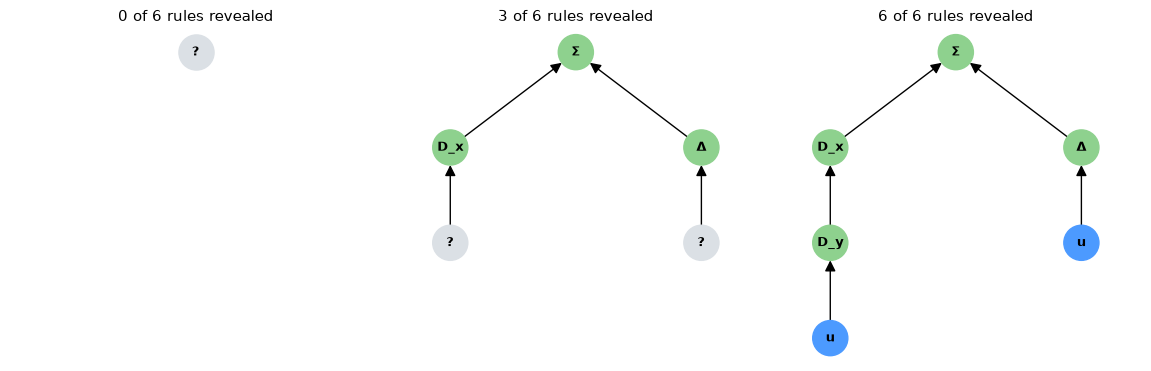

In [5]:
rules = encode(wave.truth, LEAVES)
prefix_length = 3
masked, _, allowed, target = training_rows(rules, LEAVES)[prefix_length]

print("Complete derivation:", " → ".join(rules))
print("Masked derivation:", " → ".join(TOKENS[i] for i in masked[:len(rules)]))
print("Legal next rules:", ", ".join(np.asarray(TOKENS)[allowed]))
print("Training target:", TOKENS[target])
plot_trajectory(rules, LEAVES)
plt.show()

All three samplers start from the same pool. On this benchmark, the pool excludes the mixed derivative. Guided diffusion weights training graphs using validation error, complexity, coefficient support, and mild-shuffle instability. Unguided diffusion omits the instability term from its training weights. Random grammar search draws from the prior. All three choose finalists using the same score.

Each method stops after the same number of **unique** evaluations.

In [6]:
pool = initial_pool(LEAVES, SEED, exclude=True)
torch.set_num_threads(1)
demo_log = StringIO()

with threadpool_limits(limits=1):
    demo_runs = [
        search(wave, scorer, LEAVES, pool, SEED, method, DEMO_BUDGET, demo_log)
        for method in METHODS
    ]

show_table(
    ("Sampler", "Unique evaluations", "Duplicates", "Finalist branches", "Score", "Held-out weak NMSE"),
    ((run["method"], run["unique"], run["duplicates"], ", ".join(run["finalist"]["terms"]),
      f'{run["finalist"]["score"]:.6g}', f'{run["finalist"]["test_nmse"]:.6g}')
     for run in demo_runs),
)

| Sampler | Unique evaluations | Duplicates | Finalist branches | Score | Held-out weak NMSE |
| --- | --- | --- | --- | --- | --- |
| guided diffusion | 18 | 4 | Dᵧ(tanh(u_t)), Δ(u) | 0.0416042 | 0.0267977 |
| unguided diffusion | 18 | 17 | Δ(u) | 0.0637658 | 0.0530928 |
| random grammar | 18 | 0 | Δ(u) | 0.0637658 | 0.0530928 |

In [7]:
demo_log.seek(0)
proposals = [json.loads(line) for line in demo_log]
proposal = next(
    (entry for entry in proposals if not entry["initial"] and not entry["duplicate"]),
    None,
)
if proposal:
    print("First new proposal:", ", ".join(proposal["terms"]))
    print("Reveal order:", " → ".join(proposal["reveal_order"]))

First new proposal: (u·u_t)
Reveal order: 1 branch → mul → u → u_t


## 5. A · Unrestricted graph search

The saved runs use two synthetic datasets. The isotropic benchmark seeds the true Laplacian and checks fitting and selection. The mixed benchmark tests discovery of a term absent from the starting pool. 

The plots show validation search curves and held-out weak errors. Longer runs also retain the proposed structures, fitted coefficients, and unique evaluation at which a term first appeared.

In [8]:
summary = read_results("summary.json")
extensions = read_results("extensions.json")
tuning = read_results("forecast_tuning.json")
sampler_comparison = read_results("sampler_comparison.json")
has_proposal_log = (RESULTS / "proposals.jsonl.gz").is_file()
datasets = {} if summary is None else {dataset["name"]: dataset for dataset in summary["datasets"]}
forecast_views = {}

if summary is None:
    print(f"No summary.json in {RESULTS}. See the reproduction commands below.")
else:
    print(f'{summary["budget"]} unique evaluations per run. Search seeds: {summary["seeds"]}.')
    print(summary["mesh_access"])

180 unique evaluations per run. Search seeds: [11, 22, 33, 44, 55].
Measured run pending. The official Zenodo record was reachable, but the archive was unavailable to this execution environment and no local copy was present.


### Isotropic waves

| Sampler | Truth proposed | Exact finalist | Median score | Median held-out weak NMSE | Median duplicates |
| --- | --- | --- | --- | --- | --- |
| guided diffusion | 5/5 | 5/5 | 0.00450947 | 9.13275e-06 | 120 |
| unguided diffusion | 5/5 | 5/5 | 0.00450947 | 9.13275e-06 | 116 |
| random grammar | 5/5 | 5/5 | 0.00450947 | 9.13275e-06 | 35 |

### Mixed derivative

| Sampler | Truth proposed | Exact finalist | Median score | Median held-out weak NMSE | Median duplicates |
| --- | --- | --- | --- | --- | --- |
| guided diffusion | 0/5 | 0/5 | 0.022565 | 0.0101157 | 120 |
| unguided diffusion | 0/5 | 0/5 | 0.0374019 | 0.0178641 | 119 |
| random grammar | 0/5 | 0/5 | 0.0637658 | 0.0530928 | 35 |

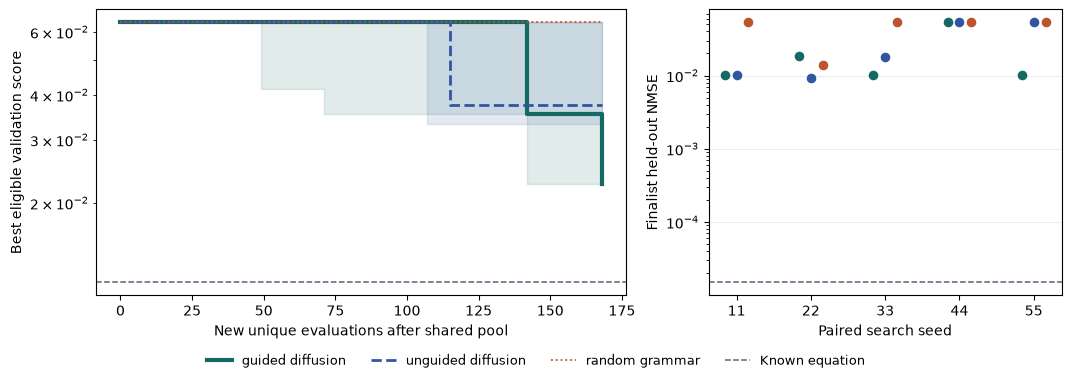

In [9]:
for dataset in datasets.values():
    display(Markdown(f'### {dataset["name"]}'))
    show_table(
        ("Sampler", "Truth proposed", "Exact finalist", "Median score",
         "Median held-out weak NMSE", "Median duplicates"),
        ((method, f"{proposed}/{n}" if dataset["truth"] else "—",
          f"{exact}/{n}" if dataset["truth"] else "—", f"{score:.6g}", f"{test_nmse:.6g}", f"{dups:g}")
         for method, exact, n, score, test_nmse, dups, proposed in method_rows(dataset)),
    )
    if not scores_are_flat(dataset):
        plot_scores(dataset)
        plt.show()

### Finalist equations and branch ablation

The equations below use the saved fitted coefficients. The ablation removes one supported term, refits the remaining coefficients on training data, and reports the resulting change in validation NMSE.

#### Isotropic waves

**Unrestricted finalist**

$$u_{tt} = 1.0112437561417034\,\Delta u$$

**Fixed-term comparator**

$$u_{tt} = 1.0112437561417034\,\Delta u$$

**Known structure, refitted**

$$u_{tt} = 1.0112437561417034\,\Delta u$$

| Model | Eligible | Held-out weak NMSE |
| --- | --- | --- |
| Unrestricted finalist | True | 9.13275e-06 |
| Fixed-term comparator | True | 9.13275e-06 |
| Known structure, refitted | True | 9.13275e-06 |

| Removed branch | Change in validation NMSE |
| --- | --- |
| Δ(u) | +0.999991 |

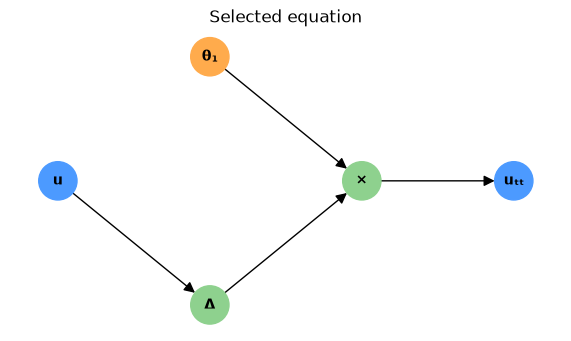

#### Mixed derivative

**Unrestricted finalist**

$$u_{tt} = -0.3753224202489147\,\partial_{yt} u + 0.8242901970408432\,\Delta u$$

**Fixed-term comparator**

$$u_{tt} = 0.8635426647180031\,\Delta u$$

**Known structure, refitted**

$$u_{tt} = 0.7452756399978079\,\partial_{xy} u + 0.8612363214870679\,\Delta u$$

| Model | Eligible | Held-out weak NMSE |
| --- | --- | --- |
| Unrestricted finalist | True | 0.0101157 |
| Fixed-term comparator | True | 0.0530928 |
| Known structure, refitted | True | 1.51118e-05 |

| Removed branch | Change in validation NMSE |
| --- | --- |
| Dᵧ(u_t) | +0.0472007 |
| Δ(u) | +0.809104 |

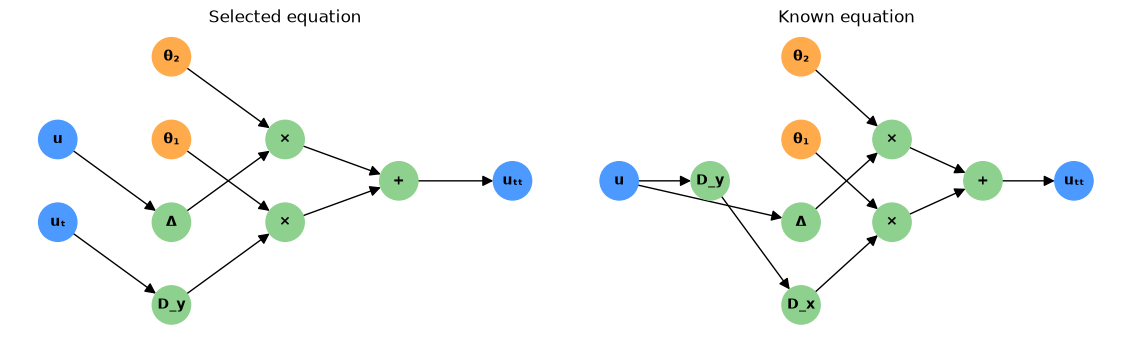

In [10]:
for dataset in datasets.values():
    display(Markdown(f'#### {dataset["name"]}'))
    winner = dataset["best"]
    models = [("Unrestricted finalist", winner),
              ("Fixed-term comparator", dataset["fixed_mask"]["finalist"])]
    if dataset.get("oracle"):
        models.append(("Known structure, refitted", dataset["oracle"]))
    display(Markdown(symbolic_equations(models)))
    show_table(
        ("Model", "Eligible", "Held-out weak NMSE"),
        ((label, fitted["eligible"], f'{fitted["test_nmse"]:.6g}') for label, fitted in models),
    )
    if winner["ablations"]:
        show_table(
            ("Removed branch", "Change in validation NMSE"),
            ((row["term"], f'{row["delta_validation"]:+.6g}') for row in winner["ablations"]),
        )
    plot_equation_graphs(dataset)
    plt.show()

### Intervention audit and local prediction

Shuffle stress tests refit the finalist at multiple shuffle widths and score the refits on clean validation fields. Time reversal scores the frozen fits on reversed held-out snapshots. The weak prediction plots compare field-derived and modeled acceleration on the original test split.

#### Isotropic waves

#### Shuffle stress test

Each draw refits the displayed graph on shuffled **training** data, then evaluates it on the same untouched validation data. Curves show medians with interquartile bands over 9 shuffles per nontrivial window. NMSE = 1 corresponds to predicting zero.

The selected graph’s median clean-validation NMSE changes from 9.473e-06 to 13.83 at 12 samples. The branch support counts at that window are Δ(u) 9/9. Passing the threshold can coexist with large coefficient drift and poor predictive accuracy.

#### Time reversal on the held-out field

The synthetic equations contain only even time derivatives. Reversing the held-out snapshots preserves the equation and flips the sign of features linear in $u_t$. The coefficients are frozen.

| Equation | Original test NMSE | Reversed test NMSE |
| --- | ---: | ---: |
| Selected graph | 9.13275e-06 | 9.00769e-06 |

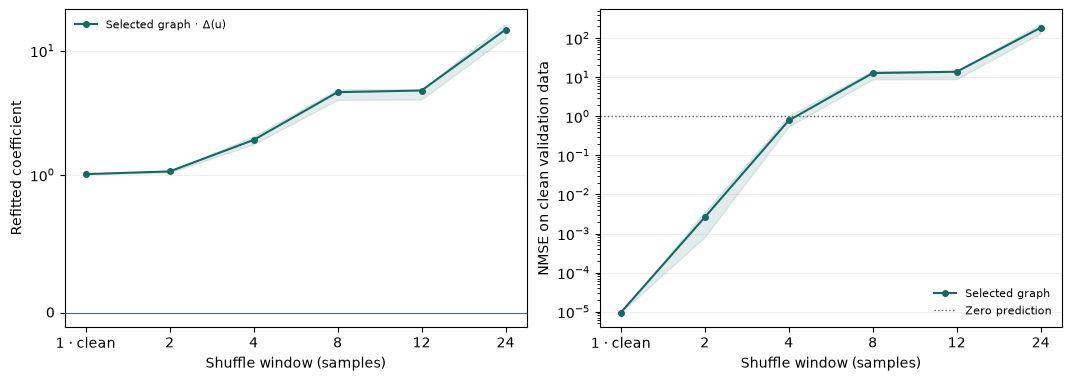

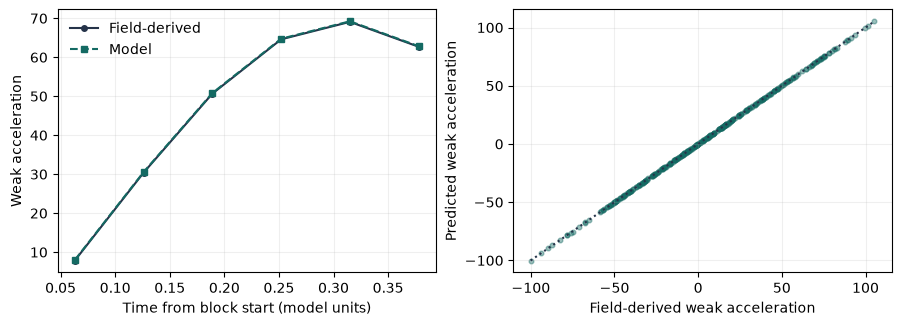

#### Mixed derivative

#### Shuffle stress test

Each draw refits the displayed graph on shuffled **training** data, then evaluates it on the same untouched validation data. Curves show medians with interquartile bands over 9 shuffles per nontrivial window. NMSE = 1 corresponds to predicting zero.

The selected graph’s median clean-validation NMSE changes from 0.01207 to 12.59 at 12 samples. The branch support counts at that window are Dᵧ(u_t) 1/9, Δ(u) 9/9. Passing the threshold can coexist with large coefficient drift and poor predictive accuracy.

#### Time reversal on the held-out field

The synthetic equations contain only even time derivatives. Reversing the held-out snapshots preserves the equation and flips the sign of features linear in $u_t$. The coefficients are frozen.

| Equation | Original test NMSE | Reversed test NMSE |
| --- | ---: | ---: |
| Selected graph | 0.0101157 | 0.198755 |
| Known equation | 1.51118e-05 | 1.44342e-05 |

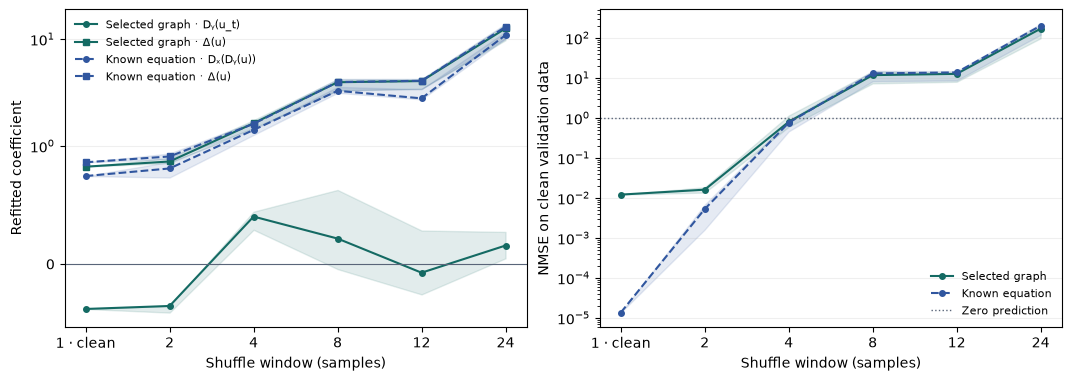

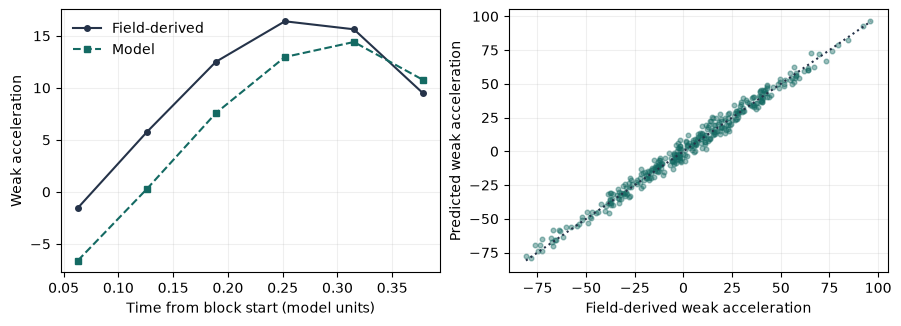

In [11]:
for dataset in datasets.values():
    display(Markdown(f'#### {dataset["name"]}'))
    display(Markdown(audit_text(dataset)))
    plot_interventions(dataset)
    plot_predictions(dataset)
    plt.show()

### A forecast from frozen coefficients

The periodic solver can propagate finalists with supported linear constant-coefficient branches. The models use the same two snapshots from the reserved time interval. This section compares the unrestricted finalist with the refitted Lab 1 equation, which uses a single Laplacian term.

#### Isotropic waves

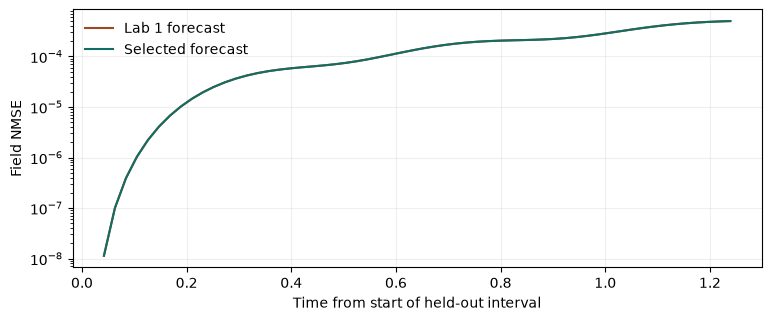

| Lab 1 mean field NMSE | Finalist mean field NMSE |
| --- | --- |
| 0.000169469 | 0.000169469 |

#### Mixed derivative

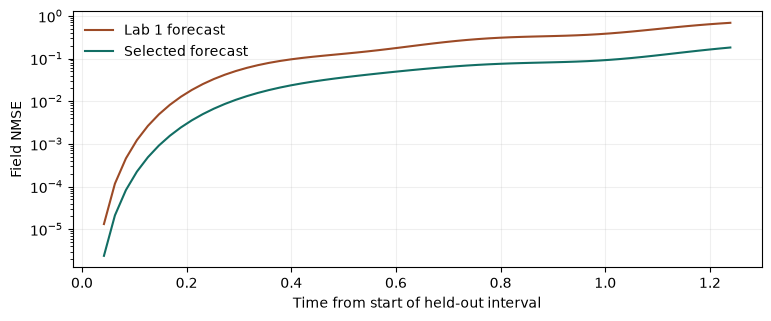

| Lab 1 mean field NMSE | Finalist mean field NMSE |
| --- | --- |
| 0.235736 | 0.0589837 |

In [12]:
for index, dataset in enumerate(datasets.values(), start=1):
    forecast = unrestricted_fields(dataset)
    if forecast is None:
        continue
    display(Markdown(f'#### {dataset["name"]}'))
    coords, fields = forecast
    fig, (baseline_nmse, selected_nmse) = selected_forecast_errors(coords, fields)
    plt.show()
    show_table(("Lab 1 mean field NMSE", "Finalist mean field NMSE"),
               [(f"{baseline_nmse:.6g}", f"{selected_nmse:.6g}")])
    forecast_views[f'A · {dataset["name"]}'] = (
        coords, fields, RESULTS / "figures" / f"unrestricted_forecast_{index:02d}.gif"
    )

## 6. B · One-branch extensions of the Lab 1 equation

The mixed-wave search starts from the Lab 1 Laplacian. The damped-wave search starts from the undamped mixed equation. Each proposes one additional branch from a shared library. Training, validation, and the three test fields have independently sampled mode mixtures. Each test forecast starts with two snapshots and scores the following 46 frames.

Sampler rows give the median across search seeds of each run's mean test-field NMSE. The graph and forecast example use the guided run with the lowest validation score.

18 evaluations per run, including the starting graph.


### Mixed waves

| Model or sampler | Exact finalists | Forecast NMSE | Runs beating Lab 1 on every test field |
| --- | --- | --- | --- |
| Lab 1, refitted | — | 0.342234 | — |
| Known structure, refitted | — | 0.00122429 | — |
| guided diffusion | 5/5 | 0.00122429 | 5/5 |
| unguided diffusion | 5/5 | 0.00122429 | 5/5 |
| random grammar | 5/5 | 0.00122429 | 5/5 |

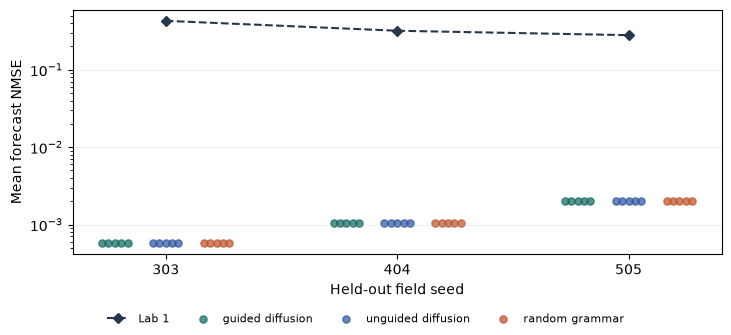

### Damped mixed waves

| Model or sampler | Exact finalists | Forecast NMSE | Runs beating Lab 1 on every test field |
| --- | --- | --- | --- |
| Lab 1, refitted | — | 2.70947 | — |
| Undamped start, refitted | — | 1.73618 | — |
| Known structure, refitted | — | 0.00126434 | — |
| guided diffusion | 4/5 | 0.00126434 | 5/5 |
| unguided diffusion | 3/5 | 0.00126434 | 5/5 |
| random grammar | 5/5 | 0.00126434 | 5/5 |

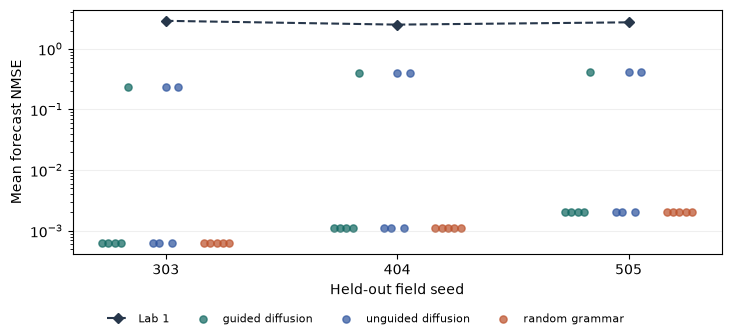

In [13]:
if extensions is None:
    print("No extensions.json is available for this run.")
else:
    print(f'{extensions["budget"]} evaluations per run, including the starting graph.')
    for benchmark in extensions["benchmarks"]:
        display(Markdown(f'### {benchmark["name"]}'))
        lab1_errors = [test["rollout_nmse"] for test in benchmark["baseline_tests"]]
        rows = [("Lab 1, refitted", "—", f"{np.mean(lab1_errors):.6g}", "—")]
        for label, key in (("Undamped start, refitted", "search_start_tests"),
                           ("Known structure, refitted", "oracle_tests")):
            if key in benchmark:
                rows.append((label, "—",
                             f'{np.mean([test["rollout_nmse"] for test in benchmark[key]]):.6g}', "—"))
        for method in METHODS:
            runs = [run for run in benchmark["runs"] if run["method"] == method]
            errors = np.array([[test["rollout_nmse"] for test in run["held_out"]] for run in runs])
            exact = sum(run["selected"]["exact_recovery"] for run in runs)
            better = int(np.all(errors < lab1_errors, axis=1).sum())
            rows.append((method, f"{exact}/{len(runs)}", f"{np.median(errors.mean(axis=1)):.6g}",
                         f"{better}/{len(runs)}"))
        show_table(("Model or sampler", "Exact finalists", "Forecast NMSE", "Runs beating Lab 1 on every test field"),
                   rows)
        sampler_forecast_errors(benchmark, extensions["field_seeds"][2:])
        plt.show()

#### Mixed waves · search seed 11, test field seed 303

**Refitted Lab 1**

$$u_{tt} = 0.9677514488907055\,\Delta u$$

**Guided finalist**

$$u_{tt} = 0.7652658325975481\,\partial_{xy} u + 0.8687889226909314\,\Delta u$$

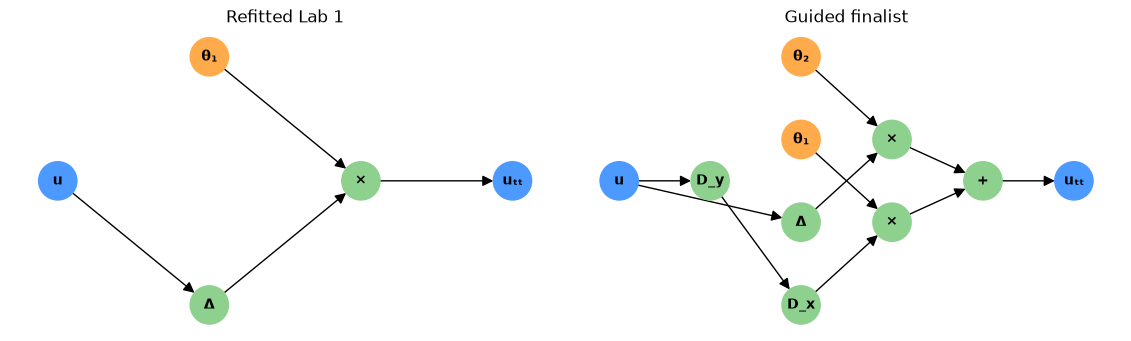

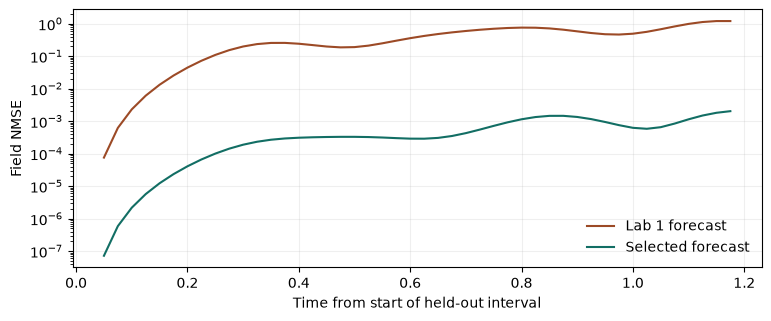

#### Damped mixed waves · search seed 11, test field seed 303

**Refitted Lab 1**

$$u_{tt} = 0.9256449899891065\,\Delta u$$

**Guided finalist**

$$u_{tt} = 0.7639906447827899\,\partial_{xy} u + 0.8686938257210131\,\Delta u - 2.1937734622789424\,\partial_t u$$

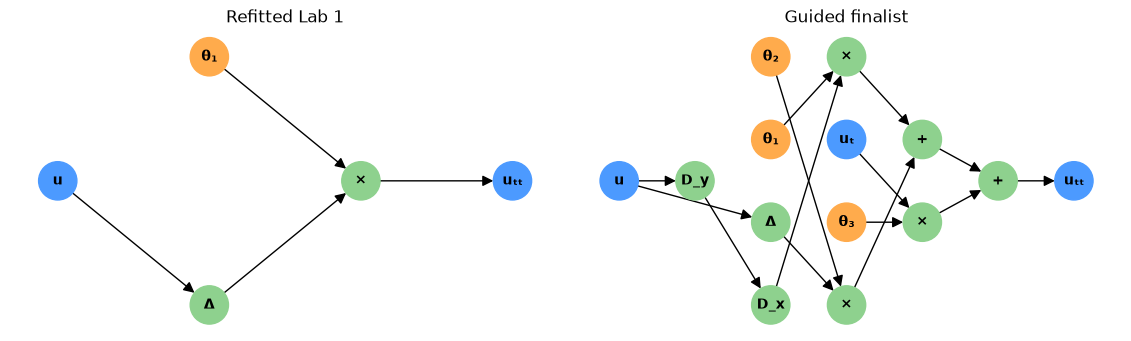

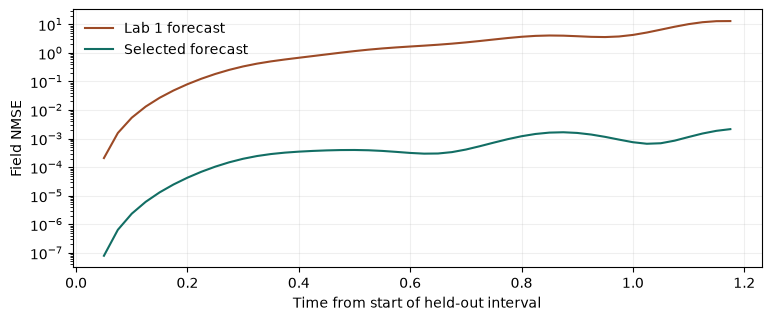

In [14]:
if extensions is not None:
    for index, benchmark in enumerate(extensions["benchmarks"], start=1):
        run = representative_run(benchmark)
        seed, coords, fields = heldout_fields(extensions, benchmark, run)
        display(Markdown(f'#### {benchmark["name"]} · search seed {run["seed"]}, test field seed {seed}'))
        models = [("Refitted Lab 1", benchmark["baseline"]), ("Guided finalist", run["selected"])]
        display(Markdown(symbolic_equations(models)))
        plot_equation_records(models)
        selected_forecast_errors(coords, fields)
        plt.show()
        forecast_views[f'B · {benchmark["name"]}'] = (
            coords, fields, RESULTS / "figures" / f"forecast_{index:02d}.gif"
        )

## 7. C · Fit coefficients to trajectories

Rollout tuning uses training trajectories to fit coefficients over multiple steps. The candidate set includes the previous graph with both finite-difference and spectral derivatives. For the unrestricted finalists, it also allows one-term replacements drawn from the pooled guided proposals. Validation rollout error chooses a candidate. The Lab 1 baseline receives its own spectral rollout fit.

The table shows the mean held-out field NMSE for each variant. The fresh fields below it use separately sampled modes and phases.

In [15]:
tuning_labels = (
    "Lab 1, rollout-tuned",
    "Original selected forecast",
    "Same graph, rollout-tuned (finite differences)",
    "Same graph, rollout-tuned (spectral)",
    "Validation-selected forecast",
)

if tuning is None:
    print("No forecast_tuning.json is available for this run.")
else:
    show_table(
        ("Benchmark", "Tuned Lab 1", "Original finalist", "Same graph, tuned FD",
         "Same graph, tuned spectral", "Validation-selected"),
        ((benchmark["name"], *(
            f'{np.mean([test["mean"] for test in benchmark["test"][label]]):.6g}'
            for label in tuning_labels
        )) for benchmark in tuning["benchmarks"]),
    )

tuned_mixed = None if tuning is None else next(
    (benchmark for benchmark in tuning["benchmarks"] if benchmark["name"] == wave.name), None
)

| Benchmark | Tuned Lab 1 | Original finalist | Same graph, tuned FD | Same graph, tuned spectral | Validation-selected |
| --- | --- | --- | --- | --- | --- |
| Isotropic waves | 9.38957e-14 | 0.000169469 | 0.000139111 | 9.38957e-14 | 9.38957e-14 |
| Mixed derivative | 0.235367 | 0.0589837 | 0.0586318 | 0.0575452 | 1.26268e-13 |
| Mixed waves | 0.334795 | 0.00122429 | 0.00132658 | 6.88827e-14 | 6.88827e-14 |
| Damped mixed waves | 2.5414 | 0.00126434 | 0.00133354 | 1.002e-13 | 1.002e-13 |

**Rollout-tuned Lab 1**

$$u_{tt} = 0.8594328300295735\,\Delta u$$

**Original finalist**

$$u_{tt} = -0.3753224202489147\,\partial_{yt} u + 0.8242901970408432\,\Delta u$$

**Validation-selected forecast**

$$u_{tt} = 0.7200000185188119\,\partial_{xy} u + 0.8499999823951856\,\Delta u$$

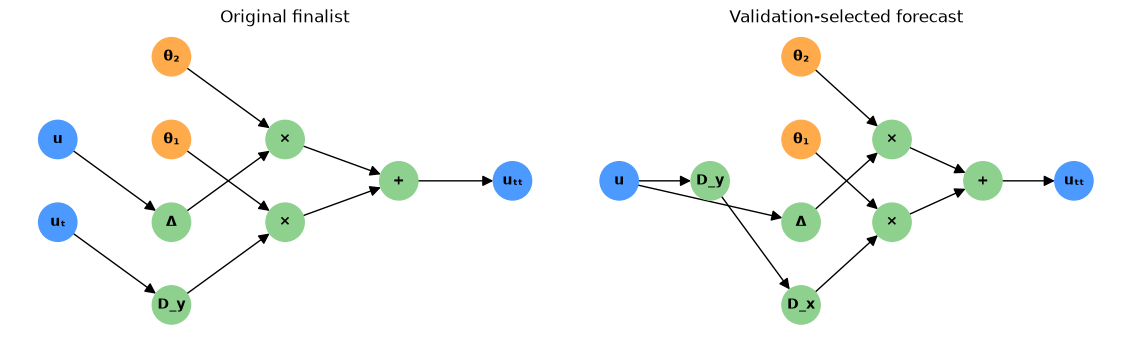

| Fresh field seed | Tuned Lab 1 | Original finalist | Validation-selected |
| --- | --- | --- | --- |
| 707 | 1.2335 | 0.941569 | 5.97718e-14 |
| 808 | 0.273855 | 0.696908 | 7.56406e-14 |
| 909 | 0.398764 | 0.742148 | 5.97988e-14 |

In [16]:
if tuned_mixed is not None:
    tuned_models = tuned_mixed["models"]
    tuned_lab1, original, chosen = (tuned_models[tuning_labels[i]] for i in (0, 1, 4))
    models = [("Rollout-tuned Lab 1", tuned_lab1), ("Original finalist", original),
              ("Validation-selected forecast", chosen)]
    display(Markdown(symbolic_equations(models)))
    plot_equation_records(models[1:])
    plt.show()
    if "extra_test" in tuned_mixed:
        show_table(
            ("Fresh field seed", "Tuned Lab 1", "Original finalist", "Validation-selected"),
            ((seed, *(f'{tuned_mixed["extra_test"][tuning_labels[j]][i]:.6g}' for j in (0, 1, 4)))
             for i, seed in enumerate(tuning["fresh_seeds"])),
        )
    tuned_coords, tuned_fields = forecast_comparison(
        synthetic(mixed=True, periodic=True), (tuned_lab1, chosen)
    )
    forecast_views[f"C · {wave.name}"] = (
        tuned_coords, tuned_fields, RESULTS / "figures" / "tuned_mixed_forecast.gif"
    )

### Residuals and evaluated horizon

Relative RMS is the spatial RMS of $\widehat u-u$ divided by the reference RMS at each frame. Lead time starts at the second initialization frame. A threshold time is the first sampled lead time where the relative residual exceeds that threshold.

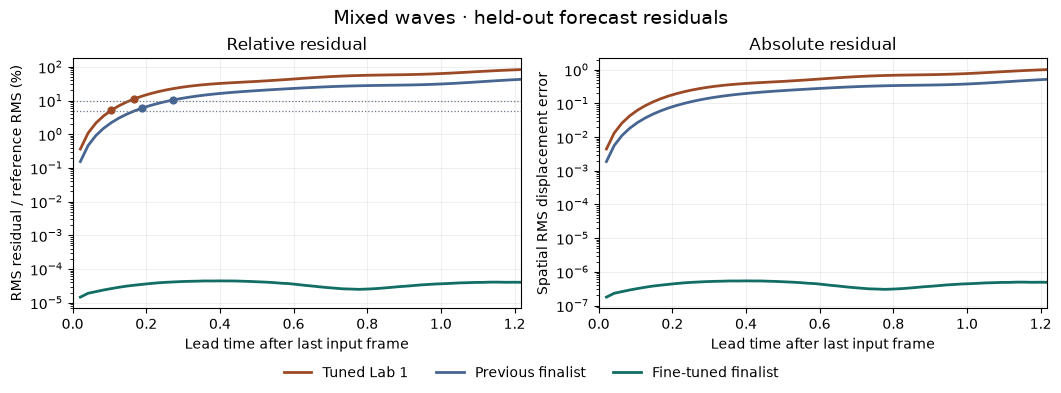

| Model | First above 5% | First above 10% |
| --- | --- | --- |
| Tuned Lab 1 | 0.105 | 0.168 |
| Previous finalist | 0.189 | 0.273 |
| Fine-tuned finalist | Below through 1.218 | Below through 1.218 |

Evaluated lead time: 1.218. Peak relative RMS of the selected forecast: 0.000044%.


In [17]:
if tuned_mixed is not None:
    fig, tolerances, crossings, horizon = tuned_residuals(tuned_mixed, tuned_coords, tuned_fields[0])
    plt.show()
    show_table(
        ("Model", *(f"First above {level}%" for level in tolerances)),
        ((label, *(f"{time:.3f}" if time is not None else f"Below through {horizon:.3f}" for time in times))
         for label, times in crossings.items()),
    )
    peak = 100 * np.sqrt(max(tuned_mixed["test"][tuning_labels[-1]][0]["curve"]))
    print(f"Evaluated lead time: {horizon:.3f}. Peak relative RMS of the selected forecast: {peak:.6f}%.")

### Conditional phase drift beyond the evaluated interval

For the Laplacian-plus-mixed-derivative spectral model, the fitted coefficients determine each mode's frequency error $\delta\omega_j$. On the original nine noise-free modes, the small-phase approximation is

$$E_{\mathrm{RMS}}(\tau)\approx \tau D,\qquad
D=\sqrt{\frac{\sum_j A_j^2(\delta\omega_j)^2}{\sum_j A_j^2}},\qquad
\tau_\varepsilon\approx\frac{\varepsilon}{D}.$$

This extrapolation assumes continuous spectral dynamics and fixed amplitudes. It omits initialization transients and future numerical accumulation. The evaluated interval comes from the rollout in the preceding cell.

| RMS threshold | Estimated lead time |
| --- | --- |
| 1% | 153,822.730 |
| 5% | 769,113.648 |
| 10% | 1,538,227.296 |

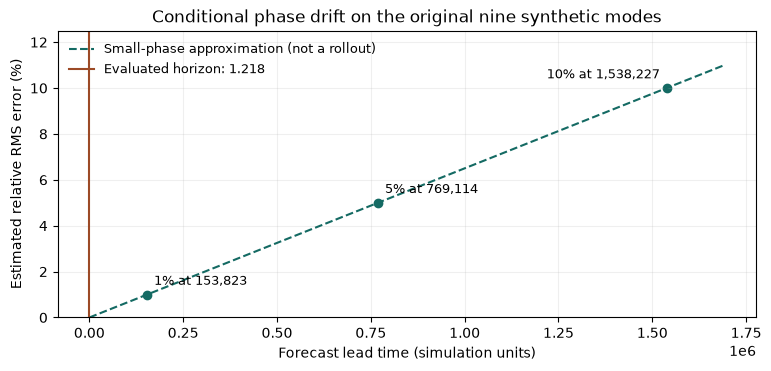

In [18]:
if tuned_mixed is not None:
    branches = tuple(map(graph_tuple, chosen["graph"]))
    if chosen.get("spectral", False) and len(branches) == 2 and set(branches) == {LAPLACIAN, MIXED}:
        try:
            drift = phase_drift_estimate(chosen)
        except ValueError as error:
            print(f"Phase drift is unavailable: {error}")
        else:
            show_table(
                ("RMS threshold", "Estimated lead time"),
                ((f"{level:.0%}", f"{time:,.3f}" if np.isfinite(time) else "Infinite in this model")
                 for level, time in zip(drift["thresholds"], drift["times"], strict=True)),
            )
            plot_phase_drift(drift, horizon)
            plt.show()
    else:
        print("The selected model falls outside the two-branch spectral phase estimate.")

## 8. Guided diffusion versus random grammar search

For each paired search seed, use only the branches that sampler proposed. Pair each eligible branch with the same Lab 1 Laplacian, fit it using the same trajectory and spectral solver, and use the same validation rule. This compares the samplers under identical forecast postprocessing.

<a id="sampler-comparison"></a>

## 6. Guided diffusion versus random search

The unrestricted mixed-wave search used 180 unique graph evaluations per seed. The original finalists were chosen by the Lab 3 validation score. For the forecast comparison, each sampler and seed supplies its own proposed branches. Each eligible branch is paired with the Lab 1 Laplacian, fitted on training trajectories using the same spectral solver, and selected by validation forecast error. The extra fitting step is a separate comparison after search.

| Metric | Guided diffusion | Random grammar |
| --- | ---: | ---: |
| Median held-out weak NMSE, original finalists | 0.0101157 | 0.0530928 |
| Median duplicate proposals | 120 | 35 |
| Exact recovery after identical forecast tuning | 4/5 | 4/5 |
| Median held-out forecast NMSE after tuning | 1.26268e-13 | 1.26268e-13 |

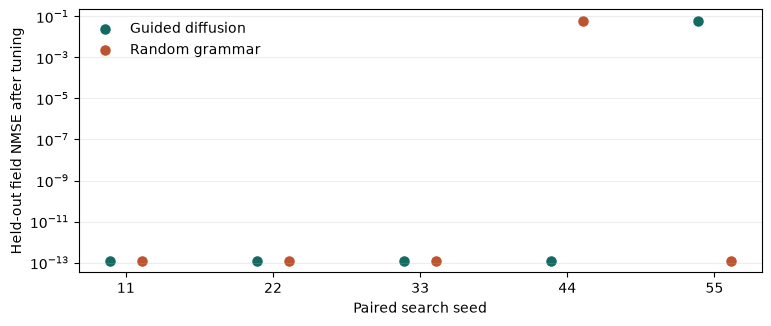

In [19]:
if sampler_comparison is not None and wave.name in datasets:
    report_sampler_comparison(sampler_comparison, datasets[wave.name])
else:
    print("The matched comparison requires sampler_comparison.json and a mixed-wave search summary.")

## 9. Proposal diversity and forecast views

The gallery counts distinct canonical graphs and shows examples from the guided search. The reverse trajectory uses a logged proposal and displays how its mask shrinks during generation.

Guided search seed 11, unique evaluation 48


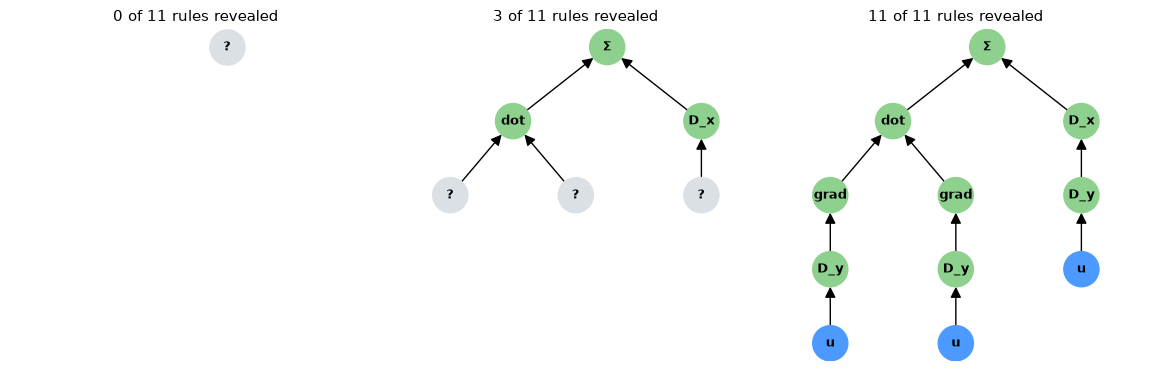

### Generated model variety

Graph counts deduplicate newly evaluated canonical equation structures across search seeds, separately for each sampler. Each run’s starting pool is excluded. Proposal totals include repeated draws. All generated structures count, regardless of their fitted coefficients or scores.

| Dataset | Sampler | Proposals | Distinct graphs | 1 branch | 2 branches | 3 branches | 4 branches |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Isotropic waves | guided diffusion | 1454 | 759 | 194 | 334 | 148 | 83 |
| Isotropic waves | unguided diffusion | 1426 | 766 | 114 | 315 | 225 | 112 |
| Isotropic waves | random grammar | 1020 | 779 | 203 | 322 | 178 | 76 |
| Mixed derivative | guided diffusion | 1453 | 755 | 141 | 354 | 184 | 76 |
| Mixed derivative | unguided diffusion | 1420 | 780 | 128 | 270 | 245 | 137 |
| Mixed derivative | random grammar | 1020 | 779 | 203 | 322 | 178 | 76 |

These examples come from guided diffusion on the mixed-derivative dataset. For each listed structure, the gallery uses the smallest available DAG, with ties by log order. An edge marked ×2 supplies the same input twice.

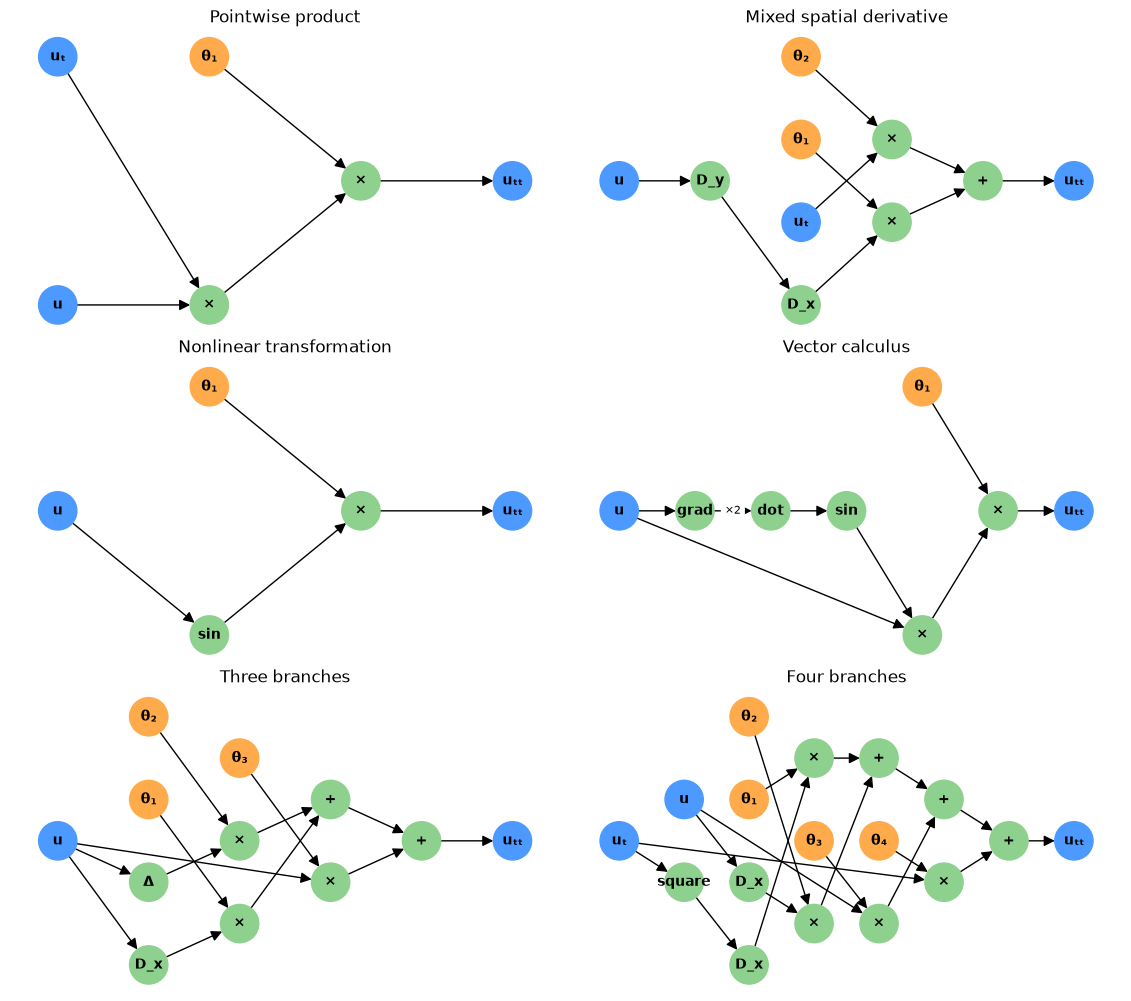

In [20]:
if has_proposal_log:
    trajectory = example_trajectory(RESULTS)
    if trajectory:
        tokens, evaluation, seed, _ = trajectory
        print(f"Guided search seed {seed}, unique evaluation {evaluation}")
        plot_trajectory(tokens)
        plt.show()
    variety_text, examples = proposal_variety(RESULTS)
    display(Markdown(variety_text))
    if examples:
        plot_equation_records(examples)
        plt.show()
else:
    print("No proposals.jsonl.gz is available for this run.")

### Field snapshots, wavefronts, and residual maps

Edit `VIEW` using the printed list. Plots compare the reference, Lab 1 forecast, and selected forecast. The wavefront contours and surfaces show the $u=0$ level sets of the superposed wave field. Enable `SHOW_ANIMATION` in the settings cell to display the saved GIF when available.

Available views: A · Isotropic waves, A · Mixed derivative, B · Mixed waves, B · Damped mixed waves, C · Mixed derivative
Displayed view: C · Mixed derivative


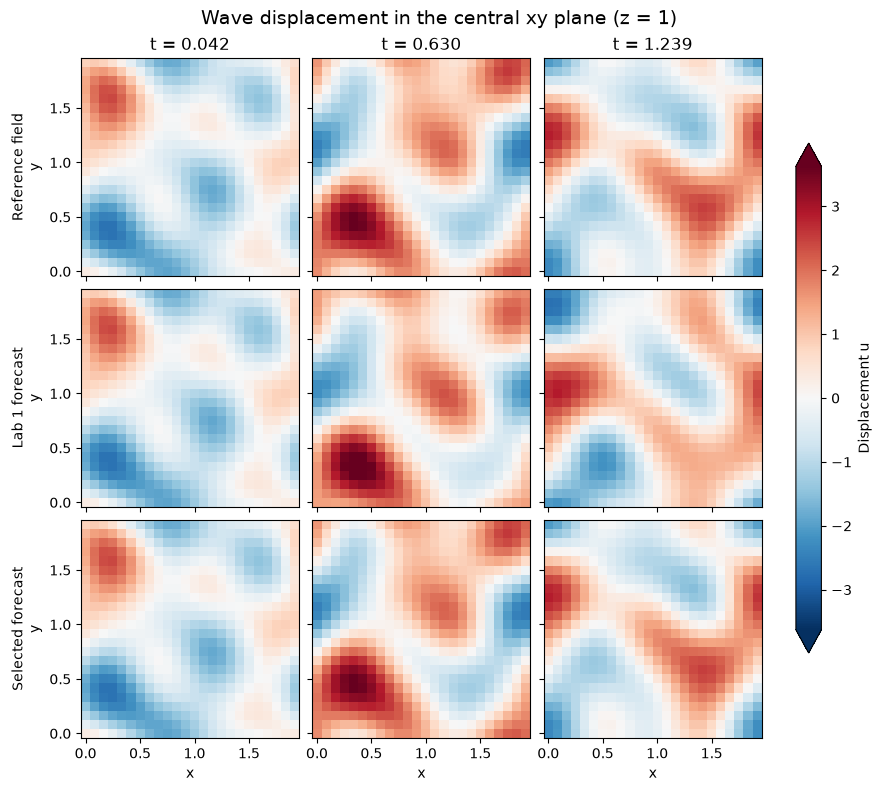

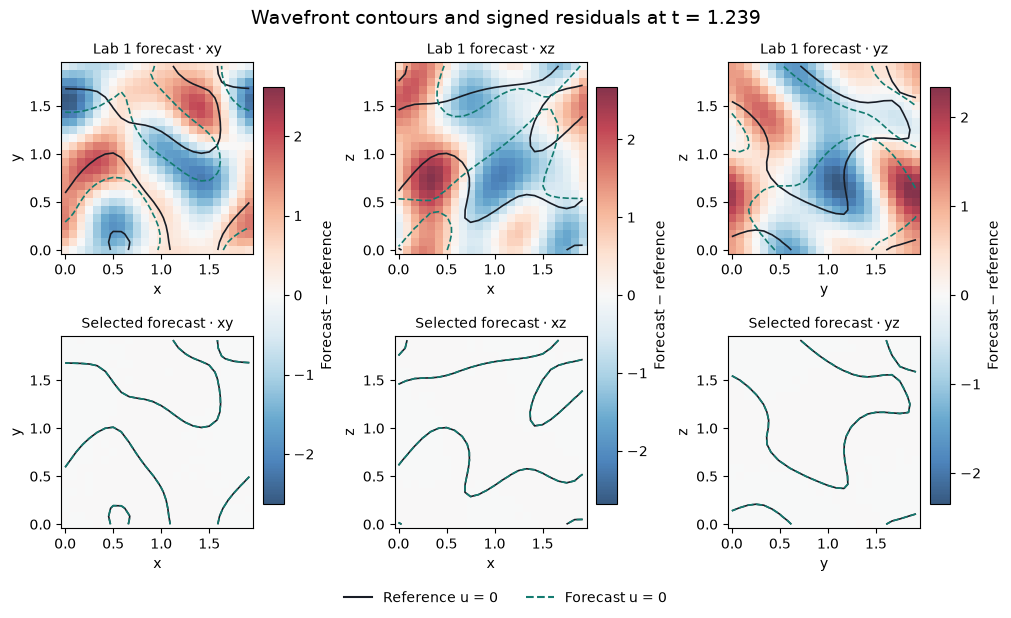

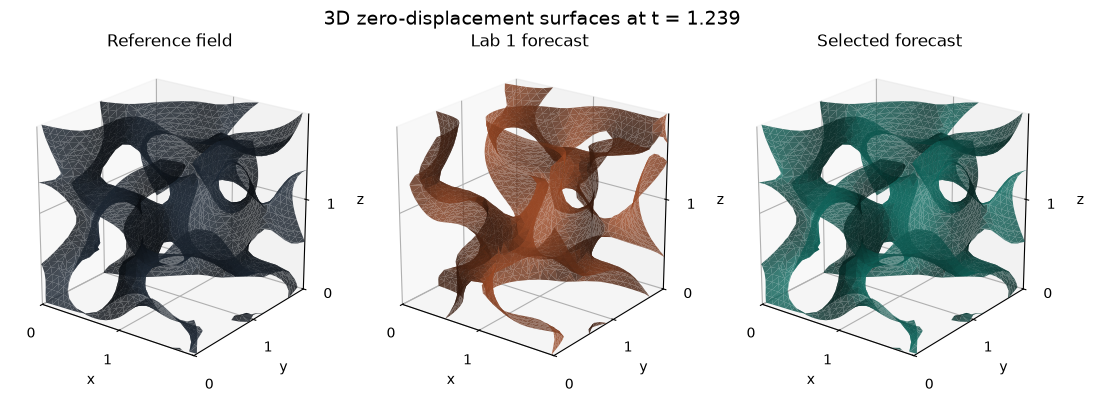

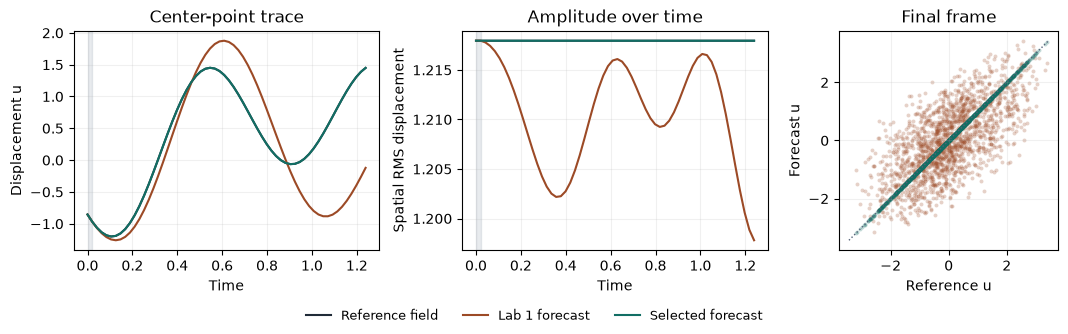

In [21]:
VIEW = "C · Mixed derivative"

if forecast_views:
    view = VIEW if VIEW in forecast_views else next(iter(forecast_views))
    print("Available views:", ", ".join(forecast_views))
    print("Displayed view:", view)
    view_coords, view_fields, animation_path = forecast_views[view]
    field_snapshots(view_coords, view_fields)
    wavefront_maps(view_coords, view_fields)
    wavefront_surfaces(view_coords, view_fields)
    forecast_diagnostics(view_coords, view_fields)
    plt.show()
    if SHOW_ANIMATION and animation_path.is_file():
        display(Image(filename=str(animation_path), width=720))

In [22]:
display(Markdown("### References\n\n" + REFERENCES))

### References

- Austin et al. (2021), [Structured Denoising Diffusion Models in Discrete State-Spaces](https://papers.neurips.cc/paper_files/paper/2021/hash/958c530554f78bcd8e97125b70e6973d-Abstract.html).
- Kusner et al. (2017), [Grammar Variational Autoencoder](https://proceedings.mlr.press/v70/kusner17a.html).
- Messenger and Bortz (2021), [Weak SINDy for Partial Differential Equations](https://doi.org/10.1016/j.jcp.2021.110525).
- Koyama et al. (2021), [MeshRIR](https://doi.org/10.5281/zenodo.10852693).
- [Membrane and temperature dissipation, Lab 2](https://github.com/mikhmed-nabiev/Membrane-and-temperature-dissipation/tree/main/lab2-heat), coefficient support and temporal interventions.